# Elkinematics Research and Experimentation Playground

This notebook serves as the central interactive sandbox and staging ground for the Elkinematics dysgraphia screening project.

### Workflow Sections:
1. **Environment and Centralized Config** - Load paths and hyperparameters from `scripts/config.py`.
2. **Centralized Model Builder** - Inspect and compile V0 (Baseline CNN), V1 (CNN+XAI), and V2 (Bi-LSTM).
3. **Data Loading and Discovery** - Scan and profile samples in `datasets/` and `val_datasets/`.
4. **Kinematic Feature Extraction** - Extract the 8 standard kinematic features (`delta_x`, `delta_y`, `pressure`, `tiltX`, `tiltY`, `velocity`, `acceleration`, `jerk`) and `latency`.
5. **Global Scaling and Preprocessing** - Normalize data using global Z-score scalers without leakage.
6. **Model Training and Tuning** - Train models with callbacks (EarlyStopping, ReduceLROnPlateau).
7. **Inference and Explainable AI (XAI)** - Predict risk scores and render stroke-level heatmaps.
8. **Evaluation and Performance Metrics** - Accuracy, Recall, Confusion Matrix, and ROC-AUC.
9. **Interactive Sandbox / Scratchpad** - Free-form sandbox for rapid prototyping.

## 1. Environment and Centralized Configuration

In [1]:
import sys
import os
from pathlib import Path

# Ensure project root and scripts directory are accessible
PROJECT_ROOT = Path(os.getcwd()).resolve()
SCRIPTS_DIR = PROJECT_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

import config

print(f"Project Root: {config.PROJECT_ROOT}")
print(f"Max Timesteps: {config.MAX_TIMESTEPS} | Features: {config.FEATURES}")
print(f"Active Model V2 Path: {config.MODEL_PATHS['v2']}")
print(f"Scaler Path: {config.SCALER_PATH}")

Project Root: /Users/asthiseta/Project/somethinginmyeye
Max Timesteps: 500 | Features: 8
Active Model V2 Path: /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV2.keras
Scaler Path: /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz


## 2. Centralized Model Builder and Architecture Summary

In [2]:
from model_builder import build_model, load_or_build_model

# Build and inspect our flagship V2 Bi-LSTM architecture
model_v2 = build_model(version="v2")
model_v2.summary()

Model: "elkinematics_v2_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ kinematics_input    │ (None, 500, 8)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_1            │ (None, 500, 128)  │     37,376 │ kinematics_input… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 500, 128)  │          0 │ bilstm_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_2            │ (None, 500, 64)   │     41,216 │ dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latency_input       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 500, 64)   │          0 │ bilstm_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_latency      │ (None, 500, 1)    │          0 │ latency_input[0]… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_modalities   │ (None, 500, 65)   │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ repeat_latency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ heatmap_output      │ (None, 500, 1)    │         66 │ concat_modalitie… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,658 (307.26 KB)

 Trainable params: 78,658 (307.26 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Data Loading and Discovery

In [3]:
import glob

train_files = glob.glob(os.path.join(config.DATASET_DIR, "*.csv"))
val_files = glob.glob(os.path.join(config.VAL_DATASET_DIR, "*.csv"))

train_normal = [f for f in train_files if "normal" in os.path.basename(f).lower()]
train_dyslexic = [f for f in train_files if ("dyslexia" in os.path.basename(f).lower() or "dysgraphia" in os.path.basename(f).lower())]

print(f"Training Set:   {len(train_files)} files (Normal: {len(train_normal)}, Dysgraphic/Dyslexic: {len(train_dyslexic)})")
print(f"Validation Set: {len(val_files)} files")

Training Set:   872 files (Normal: 436, Dysgraphic/Dyslexic: 436)
Validation Set: 218 files


## 4. Kinematic Feature Extraction (8 Kinematics Features and Latency)

In [ ]:
from universal_pipeline import extract_universal_features

sample_csv = os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
if os.path.exists(sample_csv):
    sample_df = pd.read_csv(sample_csv)
    features_array = extract_universal_features(sample_df)
    print(f"Raw sample shape: {sample_df.shape}")
    print(f"Extracted feature tensor shape: {features_array.shape} (Timesteps x 9 internal features)")
    print("Feature columns:", config.FEATURE_NAMES + ["dt"])
else:
    print(f"Sample not found at {sample_csv}")

## 5. Global Scaling and Preprocessing Pipeline

In [4]:
from universal_pipeline import load_and_scale_universal, load_validation_with_train_scalers, get_v2_data

# 1. Load and compute global scalers on training data
print("Processing Training Cohort...")
X_train_seq_scaled, X_train_lat_scaled, y_train = load_and_scale_universal(
    data_dir=config.DATASET_DIR,
    scaler_save_path=config.SCALER_PATH
)

# 2. Transform validation cohort using frozen training scalers (Strict Hold-Out, No Leakage)
print("Processing Validation Cohort with Frozen Scalers...")
X_val_seq_scaled, X_val_lat_scaled, y_val = load_validation_with_train_scalers(
    data_dir=config.VAL_DATASET_DIR,
    scaler_path=config.SCALER_PATH
)

# 3. Format inputs for V2 Multi-Input Model
[X_train_v2_seq, X_train_v2_lat], y_train_td = get_v2_data(X_train_seq_scaled, X_train_lat_scaled, y_train)
[X_val_v2_seq, X_val_v2_lat], y_val_td = get_v2_data(X_val_seq_scaled, X_val_lat_scaled, y_val)

print(f"Scaled Training Sequences: {X_train_v2_seq.shape}")
print(f"Scaled Validation Sequences: {X_val_v2_seq.shape}")

Processing Training Cohort...
Saved global feature scalers to: /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz
Processing Validation Cohort with Frozen Scalers...
Scaled Training Sequences: (872, 500, 8)
Scaled Validation Sequences: (218, 500, 8)


## 6. Model Training and Fine-Tuning

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Build fresh compiled V2 model
experiment_model = build_model("v2", learning_rate=config.LEARNING_RATE)

early_stop = EarlyStopping(monitor='val_loss', patience=config.EARLY_STOPPING_PATIENCE, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=config.REDUCE_LR_PATIENCE, min_lr=config.MIN_LR, verbose=1)

# Optional: Set to True to train interactive experiment
TRAIN_EXPERIMENT = False

if TRAIN_EXPERIMENT:
    history = experiment_model.fit(
        [X_train_v2_seq, X_train_v2_lat], y_train_td,
        validation_data=([X_val_v2_seq, X_val_v2_lat], y_val_td),
        epochs=config.EPOCHS,
        batch_size=config.BATCH_SIZE,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
else:
    print("Training skipped. Set TRAIN_EXPERIMENT = True to run full training cycle.")

## 7. Inference and Explainable AI (XAI) Heatmap Inspection

Loading existing V2 model weights from /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV2.keras...
Sample: sample_normal.csv
Risk Score: 0.1623 -> Typical / Normal


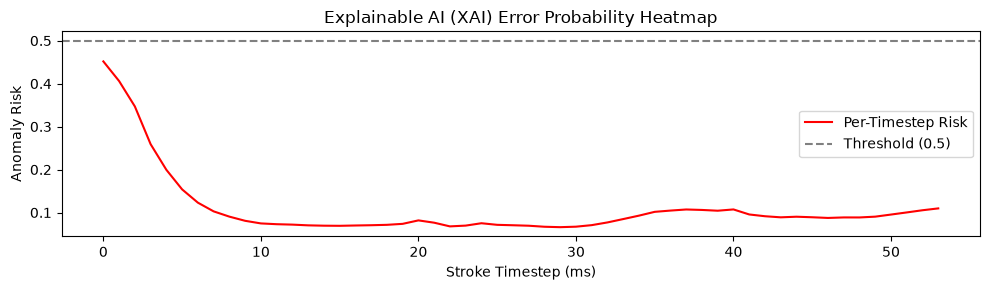

In [8]:
from universal_pipeline import unified_predict

# Load production trained model
prod_model = load_or_build_model("v2", filepath=config.MODEL_PATHS["v2"])

test_sample_path = os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
if os.path.exists(test_sample_path):
    test_df = pd.read_csv(test_sample_path)
    score, heatmap = unified_predict(test_df, prod_model, version="v2", scaler_path=config.SCALER_PATH)
    
    print(f"Sample: {os.path.basename(test_sample_path)}")
    print(f"Risk Score: {score:.4f} -> {'Atypical / Dysgraphic' if score > 0.5 else 'Typical / Normal'}")
    
    # Plot XAI Risk Heatmap across stroke timesteps
    plt.figure(figsize=(10, 3))
    plt.plot(heatmap[:len(test_df)], color='red', label='Per-Timestep Risk')
    plt.axhline(0.5, color='gray', linestyle='--', label='Threshold (0.5)')
    plt.title("Explainable AI (XAI) Error Probability Heatmap")
    plt.xlabel("Stroke Timestep (ms)")
    plt.ylabel("Anomaly Risk")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Test sample not found at {test_sample_path}")

## 8. Evaluation and Metrics

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

# Generate predictions on validation set
val_preds_td = prod_model.predict([X_val_v2_seq, X_val_v2_lat], verbose=0)
# Aggregate time-distributed output to sequence-level score
val_scores = np.mean(val_preds_td[:, :, 0], axis=1)
val_binary_preds = (val_scores > config.CLASSIFICATION_THRESHOLD).astype(int)

acc = accuracy_score(y_val, val_binary_preds)
rec = recall_score(y_val, val_binary_preds)
prec = precision_score(y_val, val_binary_preds)
f1 = f1_score(y_val, val_binary_preds)
auc = roc_auc_score(y_val, val_scores)

print("=" * 40)
print("MODEL V2 VALIDATION METRICS")
print("=" * 40)
print(f"Accuracy : {acc * 100:.2f}%")
print(f"Recall   : {rec * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")
print(f"ROC-AUC  : {auc:.4f}")
print("=" * 40)

## 9. Multi-Stream Specific Learning Disorder (SLD) Differential Screening
Evaluates handwriting samples through the dual-stream framework:
- **Kinematic Motoric Stream:** Bi-LSTM evaluating the 8 kinematic features for Motor Dysgraphia.
- **Orthographic & Reversal Stream:** Detects b/d and p/q mirror reversals and phonological spelling distance for Dyslexia.
- **Cognitive Initiation Latency:** Working memory threshold (> 1500 ms).
- **Multi-Attribute DSM-5 Categorizer:** Typical Development, Motor Dysgraphia, Dyslexia, Comorbid SLD.

In [1]:
from sld_integrator import evaluate_sld_differential
import pandas as pd
import glob

# Test on sample cohort
sample_files = glob.glob(f"{config.SAMPLE_DIR}/*.csv")
print(f"Discovered {len(sample_files)} sample files for SLD differential evaluation:")

for sample_file in sorted(sample_files):
    sample_name = sample_file.split("/")[-1]
    prompt_target = "bebek" if "bebek" in sample_name else "b"
    df_sample = pd.read_csv(sample_file)
    
    result = evaluate_sld_differential(
        df=df_sample,
        model=prod_model,
        expected_prompt=prompt_target
    )
    
    print(f"=== Sample: {sample_name} (Prompt: '{prompt_target}') ===")
    print(f"DSM-5 Diagnosis: {result['dsm5_diagnosis']}")
    print(f"Clinical Severity: {result['clinical_severity']}")
    print(f"Dysgraphia Risk: {result['dysgraphia_risk_percentage']}%")
    print(f"Dyslexia Risk: {result['dyslexia_risk_percentage']}%")
    print(f"Letter Reversal: {result['reversal_detected']} ({result['reversal_description']})")
    print(f"Cognitive Latency: {result['cognitive_latency_ms']} ms (Exceeds: {result['latency_exceeds_threshold']})")


ModuleNotFoundError: No module named 'sld_integrator'

## 10. In-House Dual-Head Reversal Classifier (DHRC): Ingestion, Training & Evaluation

This section trains and evaluates the in-house **Dual-Head Reversal Classifier (DHRC)** using a hybrid optimization strategy:
- **Baseline Character Feature Backbone:** Ingests UJIpenchars2 (6,240 authentic Latin alphabet samples: 120 per character across 52 classes, strictly excluding digits).
- **Clinical Tablet Adaptation:** Combines `dhrc_train_datasets/` (902 raw isolated Latin letter samples: 443 Typical, 459 Atypical).
- **Strict Clinical Holdout:** Evaluates on `dhrc_val_datasets/` (198 pure authentic local tablet recordings, 100% unaugmented).
- **Zero-Digit Invariant:** Evaluates strictly the 52-letter Latin alphabet (`a-z`, `A-Z`) under DSM-5 SLD guidelines.
- **Gradient Conflict Decoupling:** Masks Head 1 character loss (`sample_weight=0.0`) on synthetic mirror reversals, ensuring Head 1 trains purely on canonical character geometry while Head 2 learns reversal classification.


In [40]:
import os
import sys
import glob
import numpy as np
import pandas as pd
from typing import List, Dict, Tuple, Any, Optional

# Ensure scripts directory and project root are on sys.path
SCRIPT_DIR = os.path.abspath("scripts")
PROJECT_ROOT = os.path.abspath(".")
for p in [SCRIPT_DIR, PROJECT_ROOT]:
    if p not in sys.path:
        sys.path.insert(0, p)

from config import (
    DHRC_TRAIN_DIR,
    DHRC_VAL_DIR,
    DHRC_VOCABULARY,
    DHRC_CHAR_TO_IDX,
    DHRC_SEQ_LEN,
    DHRC_FEATURES,
    DHRC_NUM_CLASSES
)

UJIPEN_PATH = "ujipendatasets/ujipenchars2.txt"

# -----------------------------------------------------------------------------
# 1. LATIN ALPHABET VOCABULARY (52 CLASSES: a-z, A-Z)
# -----------------------------------------------------------------------------
VOCABULARY = DHRC_VOCABULARY
CHAR_TO_IDX = DHRC_CHAR_TO_IDX

# Chiral reversal transformation maps
HORIZONTAL_REVERSIBLE_CHARS = {
    'b': 'd', 'd': 'b',
    'p': 'q', 'q': 'p',
    'B': 'B_rev', 'D': 'D_rev', 'E': 'E_rev', 'F': 'F_rev',
    'J': 'J_rev', 'K': 'K_rev', 'L': 'L_rev', 'N': 'N_rev',
    'P': 'P_rev', 'R': 'R_rev', 'S': 'S_rev', 'Z': 'Z_rev',
    'c': 'c_rev', 'e': 'e_rev', 's': 's_rev', 'z': 'z_rev'
}

ROTATIONAL_REVERSIBLE_CHARS = {
    'm': 'w', 'w': 'm',
    'u': 'n', 'n': 'u',
    'M': 'W', 'W': 'M'
}

# -----------------------------------------------------------------------------
# 2. UJIPENCHARS2 BENCHMARK INGESTION (LATIN ALPHABET ONLY, ZERO DIGITS)
# -----------------------------------------------------------------------------
def parse_ujipenchars_latin(filepath: str) -> List[Dict[str, Any]]:
    """Parses authentic handwriting trajectories from UJIpenchars2 for Latin characters only."""
    samples = []
    current = None
    if not os.path.isfile(filepath):
        print(f"[WARNING] UJIpenchars file not found at: {filepath}")
        return samples

    with open(filepath, 'r', encoding='latin1') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('//'):
                continue
            if line.startswith('WORD'):
                parts = line.split()
                lbl = parts[1]
                # Filter strictly for Latin alphabet (52 classes)
                if len(lbl) == 1 and lbl in CHAR_TO_IDX:
                    current = {
                        'label': lbl,
                        'sample_id': parts[2] if len(parts) > 2 else '',
                        'source': 'ujipenchars2',
                        'strokes': [],
                        'is_atypical': False
                    }
                    samples.append(current)
                else:
                    current = None
            elif line.startswith('POINTS') and current:
                if '#' in line:
                    pts_str = line.split('#')[1].strip()
                    nums = [float(v) for v in pts_str.split()]
                    pts = [(nums[i], nums[i+1]) for i in range(0, len(nums), 2)]
                    current['strokes'].append(pts)
    return samples

# -----------------------------------------------------------------------------
# 3. LOCAL TABLET SAMPLE LOADER
# -----------------------------------------------------------------------------
def load_tablet_samples_from_dir(dataset_dir: str) -> List[Dict[str, Any]]:
    """Reads local tablet CSV recordings and extracts stroke trajectories."""
    samples = []
    csv_files = sorted(glob.glob(os.path.join(dataset_dir, "*.csv")))
    
    for filepath in csv_files:
        filename = os.path.basename(filepath)
        parts = filename.split('_')
        if len(parts) < 4:
            continue
            
        mode = parts[1].lower()
        if parts[-1].isdigit() and parts[-2].isdigit():
            lbl = "_".join(parts[2:-3])
        elif parts[-1].isdigit():
            lbl = "_".join(parts[2:-2])
        else:
            lbl = parts[2]
            
        if len(lbl) != 1 or lbl not in CHAR_TO_IDX:
            continue
            
        try:
            df = pd.read_csv(filepath)
            if 'x' not in df.columns or 'y' not in df.columns:
                continue
                
            touching = df['touching'].values if 'touching' in df.columns else np.ones(len(df))
            time_vals = df['time'].values if 'time' in df.columns else np.arange(len(df))
            
            strokes = []
            curr_stroke = []
            for i in range(len(df)):
                if touching[i] == 1:
                    if curr_stroke and i > 0 and (time_vals[i] - time_vals[i-1]) > 80.0:
                        if len(curr_stroke) >= 2:
                            strokes.append(curr_stroke)
                        curr_stroke = []
                    curr_stroke.append((float(df['x'].iloc[i]), float(df['y'].iloc[i])))
                else:
                    if len(curr_stroke) >= 2:
                        strokes.append(curr_stroke)
                    curr_stroke = []
            if len(curr_stroke) >= 2:
                strokes.append(curr_stroke)
                
            if strokes:
                samples.append({
                    'label': lbl,
                    'sample_id': filename,
                    'source': os.path.basename(dataset_dir),
                    'strokes': strokes,
                    'is_atypical': ("dyslexia" in mode or "dysgraphia" in mode)
                })
        except Exception:
            continue
            
    return samples

print("Ingesting datasets for Hybrid Training...")
ujipen_samples = parse_ujipenchars_latin(UJIPEN_PATH)
local_train_samples = load_tablet_samples_from_dir(DHRC_TRAIN_DIR)
local_val_samples = load_tablet_samples_from_dir(DHRC_VAL_DIR)

# Combine for training: UJIpenchars baseline (6,240) + Local Tablet recordings (902)
train_samples = ujipen_samples + local_train_samples
val_samples = local_val_samples

print(f"UJIpenchars2 Latin samples loaded: {len(ujipen_samples)} (120 per character across 52 classes).")
print(f"Local tablet training samples:    {len(local_train_samples)} from '{DHRC_TRAIN_DIR}'.")
print(f"Total Combined Training Corpus:   {len(train_samples)} samples.")
print(f"Pure Validation Holdout:          {len(val_samples)} authentic tablet samples from '{DHRC_VAL_DIR}'.")
print(f"Vocabulary: 52 Latin classes (strictly zero digits).")


Ingesting datasets for Hybrid Training...
UJIpenchars2 Latin samples loaded: 6240 (120 per character across 52 classes).
Local tablet training samples:    928 from '/Users/asthiseta/Project/somethinginmyeye/dhrc_train_datasets'.
Total Combined Training Corpus:   7168 samples.
Pure Validation Holdout:          198 authentic tablet samples from '/Users/asthiseta/Project/somethinginmyeye/dhrc_val_datasets'.
Vocabulary: 52 Latin classes (strictly zero digits).


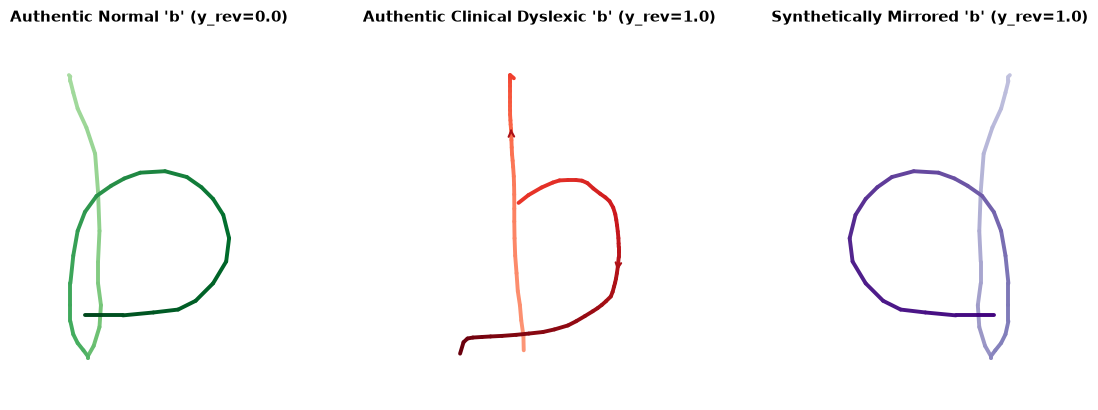

In [41]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def get_sample_bounding_box(strokes: List[List[Tuple[float, float]]]) -> Tuple[float, float, float, float]:
    all_x = [pt[0] for stroke in strokes for pt in stroke]
    all_y = [pt[1] for stroke in strokes for pt in stroke]
    if not all_x or not all_y:
        return 0.0, 1.0, 0.0, 1.0
    return min(all_x), max(all_x), min(all_y), max(all_y)

def plot_strokes_with_trajectory(ax, strokes, title, color_map="Blues"):
    """Plots trajectory with progressive directional color gradients and flow arrows."""
    cmap = plt.get_cmap(color_map)
    min_x, max_x, min_y, max_y = get_sample_bounding_box(strokes)
    total_pts = sum(len(s) for s in strokes)
    pt_counter = 0
    
    for s_idx, stroke in enumerate(strokes):
        if not stroke:
            continue
        xs = [pt[0] for pt in stroke]
        ys = [pt[1] for pt in stroke]
        
        for i in range(len(stroke) - 1):
            t = (pt_counter + i) / max(total_pts - 1, 1)
            ax.plot(
                [xs[i], xs[i+1]], 
                [ys[i], ys[i+1]], 
                color=cmap(0.35 + 0.65 * t), 
                linewidth=2.8, 
                solid_capstyle='round'
            )
            
            if len(stroke) >= 4 and i == len(stroke) // 2:
                ax.annotate(
                    '', 
                    xy=(xs[i+1], ys[i+1]), 
                    xytext=(xs[i], ys[i]),
                    arrowprops=dict(arrowstyle="->", color=cmap(0.85), lw=1.5)
                )
        pt_counter += len(stroke)
        
    margin_x = max((max_x - min_x) * 0.15, 0.05)
    margin_y = max((max_y - min_y) * 0.15, 0.05)
    ax.set_xlim(min_x - margin_x, max_x + margin_x)
    ax.set_ylim(max_y + margin_y, min_y - margin_y)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
    ax.axis('off')

# Find representative samples for visual inspection
sample_norm = next((s for s in local_train_samples if s['label'] == 'b' and not s['is_atypical']), local_train_samples[0])
sample_atyp = next((s for s in local_train_samples if s['label'] == 'b' and s['is_atypical']), local_train_samples[1])

min_x, max_x, _, _ = get_sample_bounding_box(sample_norm['strokes'])
mirrored_strokes = [[(min_x + max_x - pt[0], pt[1]) for pt in stroke] for stroke in sample_norm['strokes']]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
plot_strokes_with_trajectory(axes[0], sample_norm['strokes'], f"Authentic Normal '{sample_norm['label']}' (y_rev=0.0)", "Greens")
plot_strokes_with_trajectory(axes[1], sample_atyp['strokes'], f"Authentic Clinical Dyslexic '{sample_atyp['label']}' (y_rev=1.0)", "Reds")
plot_strokes_with_trajectory(axes[2], mirrored_strokes, f"Synthetically Mirrored '{sample_norm['label']}' (y_rev=1.0)", "Purples")
plt.tight_layout()
plt.show()


### 10.1 Equidistant Arc-Length Resampling, Chiral Augmentation & Loss Decoupling

1. **Equidistant Arc-Length Parameterization ($T=64$):** Standardizes coordinate trajectories while preserving authentic aspect ratios and air-stroke transitions.
2. **8 Kinematic Feature Channels ($F=8$):** $[\Delta x, \Delta y, \cos\theta, \sin\theta, \Delta\theta, d^2x, d^2y, \text{pen\_state}]$.
3. **Decoupled Dual-Task Loss Weighting (`sample_weight`):**
   - For all authentic samples ($y_{\text{rev}} = 0.0$ or authentic atypical): `char_sample_weight = 1.0`, `rev_sample_weight = 1.0`.
   - For synthetically mirrored chiral letters: `char_sample_weight = 0.0`, `rev_sample_weight = 1.0`.
   - **Why?** A mirrored `'b'` forms a physical `'d'`. Masking character loss on synthetic flips prevents conflicting gradients on Head 1, allowing Head 1 to learn authentic Latin geometry while Head 2 learns reversal classification.
4. **Validation Set:** Strictly unaugmented authentic tablet holdout.


In [42]:
def resample_and_normalize_sample(
    sample: Dict[str, Any], 
    target_len: int = DHRC_SEQ_LEN
) -> Dict[str, np.ndarray]:
    """Resamples stroke trajectories to fixed length T with arc-length equidistant sampling."""
    strokes = sample.get('strokes', [])
    if not strokes or sum(len(s) for s in strokes) == 0:
        return {
            'x': np.zeros(target_len, dtype=np.float32),
            'y': np.zeros(target_len, dtype=np.float32),
            'pen_state': np.zeros(target_len, dtype=np.float32)
        }

    raw_x, raw_y, raw_pen = [], [], []
    for s_idx, stroke in enumerate(strokes):
        if not stroke:
            continue
        if s_idx > 0 and len(raw_x) > 0:
            raw_x.append(stroke[0][0])
            raw_y.append(stroke[0][1])
            raw_pen.append(0.0)  # Air-stroke transition
        for pt in stroke:
            raw_x.append(float(pt[0]))
            raw_y.append(float(pt[1]))
            raw_pen.append(1.0)  # On-surface writing

    raw_x = np.array(raw_x, dtype=np.float64)
    raw_y = np.array(raw_y, dtype=np.float64)
    raw_pen = np.array(raw_pen, dtype=np.float64)

    min_x, max_x = np.min(raw_x), np.max(raw_x)
    min_y, max_y = np.min(raw_y), np.max(raw_y)
    scale = max(max_x - min_x, max_y - min_y, 1e-6)

    norm_x = (raw_x - min_x) / scale
    norm_y = (raw_y - min_y) / scale

    dx = np.diff(norm_x)
    dy = np.diff(norm_y)
    step_distances = np.sqrt(dx**2 + dy**2)
    cum_dist = np.empty(len(norm_x), dtype=np.float64)
    cum_dist[0] = 0.0
    cum_dist[1:] = np.cumsum(step_distances)
    total_length = cum_dist[-1]

    if total_length < 1e-6:
        return {
            'x': np.full(target_len, norm_x[0], dtype=np.float32),
            'y': np.full(target_len, norm_y[0], dtype=np.float32),
            'pen_state': np.ones(target_len, dtype=np.float32)
        }

    query_dist = np.linspace(0.0, total_length, target_len)
    res_x = np.interp(query_dist, cum_dist, norm_x).astype(np.float32)
    res_y = np.interp(query_dist, cum_dist, norm_y).astype(np.float32)
    interp_pen = np.interp(query_dist, cum_dist, raw_pen)
    res_pen = (interp_pen >= 0.5).astype(np.float32)

    return {'x': res_x, 'y': res_y, 'pen_state': res_pen}

def extract_reversal_kinematic_features(
    resampled_data: Dict[str, np.ndarray],
    eps: float = 1e-7
) -> np.ndarray:
    """Extracts an 8-dimensional kinematic and geometric trajectory feature matrix."""
    x = resampled_data['x']
    y = resampled_data['y']
    pen_state = resampled_data['pen_state']
    T = len(x)

    dx = np.empty(T, dtype=np.float32)
    dy = np.empty(T, dtype=np.float32)
    dx[0], dy[0] = 0.0, 0.0
    dx[1:] = np.diff(x)
    dy[1:] = np.diff(y)

    ds = np.sqrt(dx**2 + dy**2) + eps
    cos_theta = dx / ds
    sin_theta = dy / ds

    d_theta = np.zeros(T, dtype=np.float32)
    d_theta[1:] = sin_theta[1:] * cos_theta[:-1] - cos_theta[1:] * sin_theta[:-1]

    d2x = np.zeros(T, dtype=np.float32)
    d2y = np.zeros(T, dtype=np.float32)
    d2x[1:] = np.diff(dx)
    d2y[1:] = np.diff(dy)

    return np.column_stack([
        dx, dy, cos_theta, sin_theta, d_theta, d2x, d2y, pen_state.astype(np.float32)
    ])

# -----------------------------------------------------------------------------
# BUILD TRAINING TENSORS WITH DECOUPLED LOSS WEIGHTS
# -----------------------------------------------------------------------------
X_train_list, y_char_train_list, y_rev_train_list = [], [], []
sw_char_train_list, sw_rev_train_list = [], []

for s in train_samples:
    lbl = s['label']
    c_idx = CHAR_TO_IDX[lbl]
    is_atyp = s['is_atypical']
    
    # 1. Authentic sample (Both heads learn)
    res_auth = resample_and_normalize_sample(s)
    feat_auth = extract_reversal_kinematic_features(res_auth)
    X_train_list.append(feat_auth)
    y_char_train_list.append(c_idx)
    y_rev_train_list.append(1.0 if is_atyp else 0.0)
    sw_char_train_list.append(1.0)
    sw_rev_train_list.append(1.0)
    
    # 2. Augment Normal Chiral Letters ONLY (Never flip Atypical samples)
    if not is_atyp:
        if lbl in HORIZONTAL_REVERSIBLE_CHARS:
            min_x, max_x, _, _ = get_sample_bounding_box(s['strokes'])
            mir_strokes = [[(min_x + max_x - pt[0], pt[1]) for pt in stroke] for stroke in s['strokes']]
            res_mir = resample_and_normalize_sample({'strokes': mir_strokes})
            X_train_list.append(extract_reversal_kinematic_features(res_mir))
            y_char_train_list.append(c_idx)
            y_rev_train_list.append(1.0)
            # MASK character loss on synthetic flips to avoid gradient conflict on Head 1!
            sw_char_train_list.append(0.0)
            sw_rev_train_list.append(1.0)
            
        if lbl in ROTATIONAL_REVERSIBLE_CHARS:
            min_x, max_x, min_y, max_y = get_sample_bounding_box(s['strokes'])
            rot_strokes = [[(min_x + max_x - pt[0], min_y + max_y - pt[1]) for pt in stroke] for stroke in s['strokes']]
            res_rot = resample_and_normalize_sample({'strokes': rot_strokes})
            X_train_list.append(extract_reversal_kinematic_features(res_rot))
            y_char_train_list.append(c_idx)
            y_rev_train_list.append(1.0)
            sw_char_train_list.append(0.0)
            sw_rev_train_list.append(1.0)

# -----------------------------------------------------------------------------
# BUILD VALIDATION TENSORS (100% PURE AUTHENTIC LOCAL TABLET HOLDOUT)
# -----------------------------------------------------------------------------
X_val_list, y_char_val_list, y_rev_val_list = [], [], []

for s in val_samples:
    lbl = s['label']
    c_idx = CHAR_TO_IDX[lbl]
    res_val = resample_and_normalize_sample(s)
    X_val_list.append(extract_reversal_kinematic_features(res_val))
    y_char_val_list.append(c_idx)
    y_rev_val_list.append(1.0 if s['is_atypical'] else 0.0)

X_train = np.array(X_train_list, dtype=np.float32)
y_char_train = np.array(y_char_train_list, dtype=np.int32)
y_rev_train = np.array(y_rev_train_list, dtype=np.float32).reshape(-1, 1)
sw_char_train = np.array(sw_char_train_list, dtype=np.float32)
sw_rev_train = np.array(sw_rev_train_list, dtype=np.float32)

X_val = np.array(X_val_list, dtype=np.float32)
y_char_val = np.array(y_char_val_list, dtype=np.int32)
y_rev_val = np.array(y_rev_val_list, dtype=np.float32).reshape(-1, 1)

print("Tensors constructed successfully:")
print(f"  Training Corpus:    X={X_train.shape}, y_char={y_char_train.shape}, y_rev={y_rev_train.shape}")
print(f"    -> Authentic (0.0): {np.sum(y_rev_train == 0.0)} | Reversed/Atypical (1.0): {np.sum(y_rev_train == 1.0)}")
print(f"    -> Char Loss Active Samples: {int(np.sum(sw_char_train))} / {len(sw_char_train)} ({len(sw_char_train)-int(np.sum(sw_char_train))} masked synthetic flips)")
print(f"  Validation Holdout: X={X_val.shape}, y_char={y_char_val.shape}, y_rev={y_rev_val.shape}")
print(f"    -> Authentic (0.0): {np.sum(y_rev_val == 0.0)} | Reversed/Atypical (1.0): {np.sum(y_rev_val == 1.0)}")


Tensors constructed successfully:
  Training Corpus:    X=(10538, 64, 8), y_char=(10538,), y_rev=(10538, 1)
    -> Authentic (0.0): 6683 | Reversed/Atypical (1.0): 3855
    -> Char Loss Active Samples: 7168 / 10538 (3370 masked synthetic flips)
  Validation Holdout: X=(198, 64, 8), y_char=(198,), y_rev=(198, 1)
    -> Authentic (0.0): 130 | Reversed/Atypical (1.0): 68


### 10.2 Centralized Architecture Compilation & Dynamic Training

- **Architecture:** Sourced directly from `build_dhrc_model()` in [`scripts/model_builder.py`](file:///Users/asthiseta/Project/somethinginmyeye/scripts/model_builder.py):
  - Shared feature extractor: 2x Conv1D + BatchNorm + MaxPool + Bidirectional GRU (32 units) + GAP + Dense(64, ReLU) + Dropout(0.35).
  - Head 1 (`char_output`): Dense(52, Softmax) predicting canonical Latin character.
  - Head 2 (`reversal_output`): Dense(1, Sigmoid) predicting clinical reversal risk.
- **Dynamic Training Strategy:** Ceiling 50 epochs with `EarlyStopping(monitor='val_reversal_output_auc', mode='max', patience=10, restore_best_weights=True)` and `ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)`.


Instantiating DHRC model from centralized model_builder...
Beginning dynamic training (Ceiling: 50 epochs, Batch Size: 32)...
Epoch 1/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - char_output_accuracy: 0.1492 - char_output_loss: 2.0945 - loss: 2.5351 - reversal_output_accuracy: 0.8893 - reversal_output_auc: 0.9366 - reversal_output_loss: 0.2921 - val_char_output_accuracy: 0.2424 - val_char_output_loss: 2.9084 - val_loss: 3.9872 - val_reversal_output_accuracy: 0.6970 - val_reversal_output_auc: 0.6313 - val_reversal_output_loss: 0.6944 - learning_rate: 0.0010
Epoch 2/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - char_output_accuracy: 0.3254 - char_output_loss: 1.2775 - loss: 1.6054 - reversal_output_accuracy: 0.9247 - reversal_output_auc: 0.9599 - reversal_output_loss: 0.2182 - val_char_output_accuracy: 0.5758 - val_char_output_loss: 1.6579 - val_loss: 3.0131 - val_reversal_output_accuracy: 0.7121 - val_reversal_output_auc: 0.6894 - val_reversal_output_loss: 0.7407 - learning_rate: 0.0

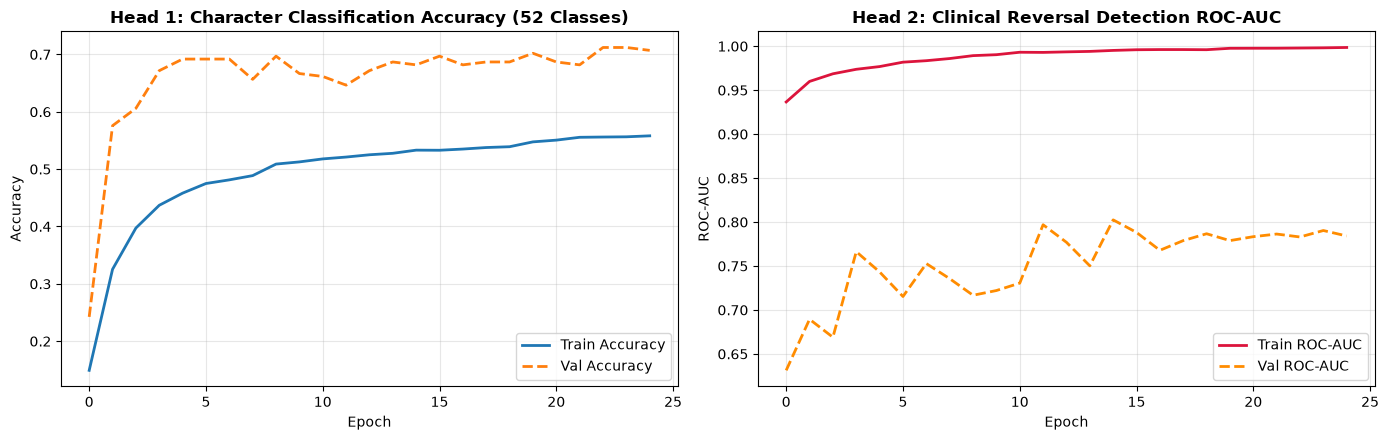

In [43]:
import os
os.environ['KERAS_HOME'] = '/tmp/keras'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from model_builder import build_dhrc_model
from config import (
    DHRC_SEQ_LEN,
    DHRC_FEATURES,
    DHRC_NUM_CLASSES,
    DHRC_EPOCHS,
    DHRC_BATCH_SIZE,
    DHRC_PATIENCE,
    DHRC_REDUCE_LR_PATIENCE,
    DHRC_MODEL_PATH
)

print("Instantiating DHRC model from centralized model_builder...")
reversal_model = build_dhrc_model(
    seq_len=DHRC_SEQ_LEN,
    num_features=DHRC_FEATURES,
    num_classes=DHRC_NUM_CLASSES
)

callbacks = [
    EarlyStopping(
        monitor='val_reversal_output_auc',
        mode='max',
        patience=DHRC_PATIENCE,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=DHRC_REDUCE_LR_PATIENCE,
        min_lr=1e-5,
        verbose=1
    )
]

print(f"Beginning dynamic training (Ceiling: {DHRC_EPOCHS} epochs, Batch Size: {DHRC_BATCH_SIZE})...")
history = reversal_model.fit(
    X_train,
    (y_char_train, y_rev_train),
    sample_weight=(sw_char_train, sw_rev_train),
    validation_data=(X_val, (y_char_val, y_rev_val)),
    epochs=DHRC_EPOCHS,
    batch_size=DHRC_BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

# Plot Training Dynamics
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Character Head Metrics
char_acc_key = next((k for k in history.history if 'char_output' in k and 'acc' in k), 'char_output_accuracy')
val_char_acc_key = f'val_{char_acc_key}'

axes[0].plot(history.history[char_acc_key], label='Train Accuracy', lw=2)
if val_char_acc_key in history.history:
    axes[0].plot(history.history[val_char_acc_key], label='Val Accuracy', lw=2, linestyle='--')
axes[0].set_title('Head 1: Character Classification Accuracy (52 Classes)', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Reversal Head Metrics
rev_auc_key = next((k for k in history.history if 'reversal_output' in k and 'auc' in k), 'reversal_output_auc')
val_rev_auc_key = f'val_{rev_auc_key}'

axes[1].plot(history.history[rev_auc_key], label='Train ROC-AUC', lw=2, color='crimson')
if val_rev_auc_key in history.history:
    axes[1].plot(history.history[val_rev_auc_key], label='Val ROC-AUC', lw=2, linestyle='--', color='darkorange')
axes[1].set_title('Head 2: Clinical Reversal Detection ROC-AUC', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('ROC-AUC')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [44]:
import tf2onnx
import onnx
import onnxruntime as ort
from config import DHRC_ONNX_PATH, DHRC_MODEL_PATH

# 1. Save Keras Model
os.makedirs(os.path.dirname(DHRC_MODEL_PATH), exist_ok=True)
reversal_model.save(DHRC_MODEL_PATH)
print(f"Trained Keras model saved to: {DHRC_MODEL_PATH}")

# Backup in scratch/
os.makedirs("scratch", exist_ok=True)
reversal_model.save("scratch/dual_head_reversal_model.keras")

# 2. Export to ONNX for Web Runtime
input_signature = [
    tf.TensorSpec(shape=(None, DHRC_SEQ_LEN, DHRC_FEATURES), dtype=tf.float32, name="trajectory_input")
]

os.makedirs(os.path.dirname(DHRC_ONNX_PATH), exist_ok=True)
onnx_model, _ = tf2onnx.convert.from_keras(
    reversal_model,
    input_signature=input_signature,
    opset=15,
    output_path=DHRC_ONNX_PATH
)

onnx_size_kb = os.path.getsize(DHRC_ONNX_PATH) / 1024.0
print(f"Exported ONNX model to: {DHRC_ONNX_PATH} ({onnx_size_kb:.2f} KB)")

# 3. Numerical Parity Verification
ort_session = ort.InferenceSession(DHRC_ONNX_PATH)
test_input = np.random.randn(4, DHRC_SEQ_LEN, DHRC_FEATURES).astype(np.float32)

keras_preds = reversal_model.predict(test_input, verbose=0)
input_name = ort_session.get_inputs()[0].name
ort_preds = ort_session.run(None, {input_name: test_input})

if ort_preds[0].shape[-1] == DHRC_NUM_CLASSES:
    ort_char, ort_rev = ort_preds[0], ort_preds[1]
else:
    ort_rev, ort_char = ort_preds[0], ort_preds[1]

diff_char = np.max(np.abs(keras_preds[0] - ort_char))
diff_rev = np.max(np.abs(keras_preds[1] - ort_rev))
print(f"ONNX Parity Difference: Character Max Diff = {diff_char:.2e}, Reversal Max Diff = {diff_rev:.2e}")
assert diff_char < 1e-4 and diff_rev < 1e-4, "ONNX numerical parity check failed!"
print("ONNX numerical parity verified successfully.")


Trained Keras model saved to: /Users/asthiseta/Project/somethinginmyeye/models/dual_head_reversal_model.keras
Exported ONNX model to: /Users/asthiseta/Project/somethinginmyeye/data_collector/models/dual_head_reversal.onnx (175.89 KB)
ONNX Parity Difference: Character Max Diff = 4.17e-07, Reversal Max Diff = 4.17e-07
ONNX numerical parity verified successfully.


### 10.3 Quantitative Evaluation & Reversal Detection Metrics

Evaluates Head 1 (52-class Top-1, case-insensitive Top-1, and Top-3 accuracy) and Head 2 (reversal discriminability) on the pure held-out tablet cohort (`dhrc_val_datasets/`).


Evaluating Dual-Head Model on Pure Validation Holdout (dhrc_val_datasets/)...
             DUAL-HEAD REVERSAL CLASSIFIER EVALUATION             
Head 1 (Character Softmax - 52 Classes):
  -> Exact Top-1 Accuracy:            68.18%
  -> Case-Insensitive Top-1 Accuracy: 84.85%
  -> Top-3 Accuracy:                  92.42%
----------------------------------------------------------------------
Head 2 (Clinical Reversal Detection):
  -> ROC-AUC Score:  0.8036
  -> Confusion Matrix:
[[116  14]
 [ 34  34]]
----------------------------------------------------------------------
Reversal Classification Report:
               precision    recall  f1-score   support

Authentic (0)       0.77      0.89      0.83       130
 Reversed (1)       0.71      0.50      0.59        68

     accuracy                           0.76       198
    macro avg       0.74      0.70      0.71       198
 weighted avg       0.75      0.76      0.75       198



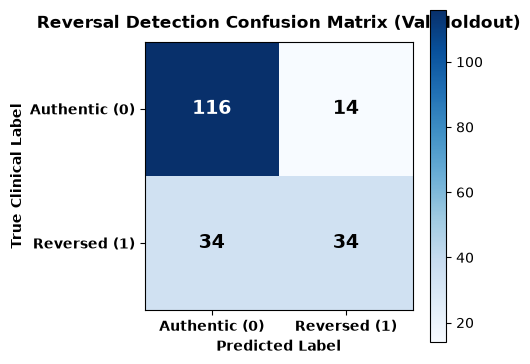

In [45]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("Evaluating Dual-Head Model on Pure Validation Holdout (dhrc_val_datasets/)...")
val_preds = reversal_model.predict(X_val, verbose=0)
char_probs = val_preds[0]
rev_probs = val_preds[1].ravel()

# Head 1: Character Classification
char_preds_top1 = np.argmax(char_probs, axis=1)
top1_acc = np.mean(char_preds_top1 == y_char_val) * 100.0

# Case-Insensitive Top-1 Accuracy (accounts for geometric homoglyphs c/C, o/O, s/S, etc.)
case_insensitive_correct = 0
for i in range(len(y_char_val)):
    pred_char = VOCABULARY[char_preds_top1[i]]
    true_char = VOCABULARY[y_char_val[i]]
    if pred_char.lower() == true_char.lower():
        case_insensitive_correct += 1
case_insensitive_acc = (case_insensitive_correct / len(y_char_val)) * 100.0

# Top-3 Accuracy
top3_correct = 0
for i in range(len(y_char_val)):
    top3_idx = np.argsort(char_probs[i])[-3:]
    if y_char_val[i] in top3_idx:
        top3_correct += 1
top3_acc = (top3_correct / len(y_char_val)) * 100.0

# Head 2: Reversal Detection
rev_preds = (rev_probs >= 0.50).astype(int)
rev_auc = roc_auc_score(y_rev_val, rev_probs)
cm = confusion_matrix(y_rev_val, rev_preds)

print("=" * 70)
print("             DUAL-HEAD REVERSAL CLASSIFIER EVALUATION             ")
print("=" * 70)
print(f"Head 1 (Character Softmax - 52 Classes):")
print(f"  -> Exact Top-1 Accuracy:            {top1_acc:.2f}%")
print(f"  -> Case-Insensitive Top-1 Accuracy: {case_insensitive_acc:.2f}%")
print(f"  -> Top-3 Accuracy:                  {top3_acc:.2f}%")
print("-" * 70)
print(f"Head 2 (Clinical Reversal Detection):")
print(f"  -> ROC-AUC Score:  {rev_auc:.4f}")
print(f"  -> Confusion Matrix:\n{cm}")
print("-" * 70)
print("Reversal Classification Report:")
print(classification_report(y_rev_val, rev_preds, target_names=['Authentic (0)', 'Reversed (1)']))
print("=" * 70)

# Visual Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
plt.colorbar(im, ax=ax)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Authentic (0)', 'Reversed (1)'], fontsize=10, fontweight='bold')
ax.set_yticklabels(['Authentic (0)', 'Reversed (1)'], fontsize=10, fontweight='bold')
ax.set_xlabel('Predicted Label', fontweight='bold')
ax.set_ylabel('True Clinical Label', fontweight='bold')
ax.set_title('Reversal Detection Confusion Matrix (Val Holdout)', fontweight='bold', pad=10)

for i in range(2):
    for j in range(2):
        text_color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


### 10.4 Interactive Stroke Tester & Single-Sample Verification

Inspects individual tablet recordings or live strokes through the trained dual-head model.


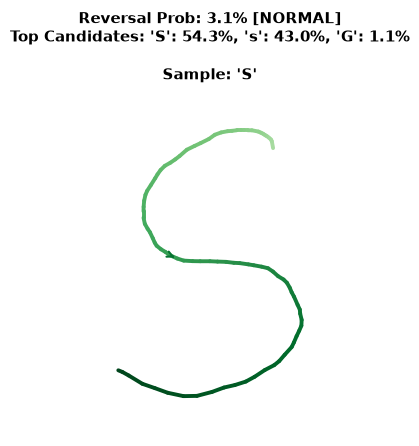

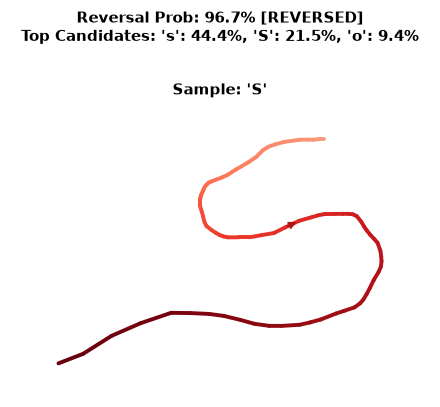

In [46]:
def test_sample_inference(sample: Dict[str, Any], model_instance=reversal_model):
    """Evaluates a single sample and plots its trajectory with dual-head prediction results."""
    res = resample_and_normalize_sample(sample)
    feats = extract_reversal_kinematic_features(res)
    inp = np.expand_dims(feats, axis=0)
    
    preds = model_instance.predict(inp, verbose=0)
    char_probs = preds[0][0]
    rev_prob = float(preds[1][0][0])
    
    top3_idx = np.argsort(char_probs)[-3:][::-1]
    top3_results = [(VOCABULARY[idx], float(char_probs[idx])) for idx in top3_idx]
    
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    color_map = "Reds" if rev_prob >= 0.50 else "Greens"
    plot_strokes_with_trajectory(ax, sample['strokes'], f"Sample: '{sample.get('label')}'", color_map)
    
    rev_tag = "[REVERSED]" if rev_prob >= 0.50 else "[NORMAL]"
    candidates_str = ", ".join([f"'{c}': {p*100:.1f}%" for c, p in top3_results])
    
    plt.suptitle(
        f"Reversal Prob: {rev_prob*100:.1f}% {rev_tag}\nTop Candidates: {candidates_str}",
        fontsize=11,
        fontweight='bold',
        y=0.98
    )
    plt.tight_layout()
    plt.show()

# Test on representative holdout samples
test_samples = [s for s in val_samples if s['label'] in ['b', 'd', 'p', 'q', 'S']][:2]
for s in test_samples:
    test_sample_inference(s)


## 11. Interactive Sandbox / Scratchpad
Dedicated scratchpad area for free-form experimentation.


In [ ]:
# Free scratchpad space for rapid interactive testing
